# Telecom Customer Churn: SQL Segmentation and Predictive Modeling

**Business problem:** Keeping an existing customer is cheaper than winning a new one. This analysis answers three questions:

1. **What is happening?** Which customer segments churn the most, and how much monthly revenue does that cost? *(SQL)*
2. **Can we see it coming?** Can we predict which current customers are likely to churn? *(Python, scikit-learn)*
3. **What should we do?** Which customers should a retention team contact first? *(risk score x revenue)*

**Data:** IBM Telco Customer Churn sample dataset. 7,043 customers, 21 columns, one row per customer. `Churn = Yes` means the customer left within the last month.

**Approach:** clean the data, segment churn in SQL (views, CTEs, window functions), compare five classification models with class balancing and cross-validated tuning, then score every customer and rank active customers by expected revenue at risk.

**Key results:**
- 26.6% of customers churned (1,869 of 7,032), about $139K in monthly charges, or roughly $1.67M a year.
- Month-to-month customers churn at 42.7% and make up 88.6% of all churners. Churn is 53.3% in the first 6 months.
- The chosen logistic regression catches 78.6% of churners (ROC AUC 0.833), up from 49.5% for the original random forest.
- 655 active customers are High risk, paying $53.1K a month. In that tier, 62.6% of customers actually churned, compared with 7.2% in the Low tier.

**Tools:** Python (pandas, NumPy, scikit-learn, matplotlib, seaborn), SQLite (Python's built-in `sqlite3`), Jupyter Notebook. SQL Server and Oracle versions of the queries and a Power BI dashboard are in this folder.

**Context:** started as master's coursework (DSC550), then expanded with SQL segmentation, better models, risk scoring and a Power BI dashboard.

**How to run:** keep `WA_Fn-UseC_-Telco-Customer-Churn.csv` in the same folder and run all cells. The notebook writes `churn_risk_scores.csv`.

## 1. Load and clean the data

In [1]:
# import libraries
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load the dataset and check its size
df_churn = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df_churn.shape

(7043, 21)

In [3]:
# TotalCharges is stored as text; errors='coerce' turns the blank values into NaN
df_churn['TotalCharges'] = pd.to_numeric(df_churn['TotalCharges'], errors='coerce')

# look at the rows with a missing TotalCharges
df_churn[df_churn['TotalCharges'].isna()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All 11 rows with a blank `TotalCharges` have **0 months of tenure** and **none of them churned**. These are brand new customers who have not been billed yet, so they have not had the chance to churn. Removing them (0.16% of the data) is cleaner than imputing a value that does not exist.

In [4]:
# remove the 11 brand new customers
df_churn = df_churn[df_churn['tenure'] > 0].copy()
df_churn.shape

(7032, 21)

## 2. SQL: what is happening?

The cleaned data is loaded into an in-memory SQLite database so the segmentation can be done in SQL. The same queries run in SQL Server with only minor syntax changes (for example `TOP 10` instead of `LIMIT 10`).

In [5]:
# create an in-memory SQLite database and load the cleaned data as a table
conn = sqlite3.connect(':memory:')
df_churn.to_sql('customers', conn, index=False)

# helper function to run a query and return a DataFrame
def run_sql(query):
    return pd.read_sql(query, conn)

### 2a. Create a feature view
A view adds two fields used throughout the analysis:
- `tenure_band`: groups months of tenure into lifecycle stages
- `num_addons`: how many of the six add-on services the customer has (a measure of engagement)

In [6]:
create_view_sql = '''
CREATE VIEW customer_features AS
SELECT
    *,
    CASE
        WHEN tenure <= 6  THEN '01: 0-6 months'
        WHEN tenure <= 12 THEN '02: 7-12 months'
        WHEN tenure <= 24 THEN '03: 13-24 months'
        WHEN tenure <= 48 THEN '04: 25-48 months'
        ELSE                   '05: 49-72 months'
    END AS tenure_band,
    (CASE WHEN OnlineSecurity   = 'Yes' THEN 1 ELSE 0 END
   + CASE WHEN OnlineBackup     = 'Yes' THEN 1 ELSE 0 END
   + CASE WHEN DeviceProtection = 'Yes' THEN 1 ELSE 0 END
   + CASE WHEN TechSupport      = 'Yes' THEN 1 ELSE 0 END
   + CASE WHEN StreamingTV      = 'Yes' THEN 1 ELSE 0 END
   + CASE WHEN StreamingMovies  = 'Yes' THEN 1 ELSE 0 END) AS num_addons,
    CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END AS churn_flag
FROM customers
'''
conn.execute(create_view_sql);

### 2b. Overall churn and monthly revenue lost

In [7]:
run_sql('''
SELECT
    COUNT(*)                                           AS customers,
    SUM(churn_flag)                                    AS churned,
    ROUND(100.0 * AVG(churn_flag), 1)                  AS churn_rate_pct,
    ROUND(SUM(MonthlyCharges * churn_flag), 0)         AS monthly_revenue_lost,
    ROUND(SUM(MonthlyCharges * churn_flag) * 12, 0)    AS annualized_revenue_lost
FROM customer_features
''')

,customers,churned,churn_rate_pct,monthly_revenue_lost,annualized_revenue_lost
0,7032,1869,26.6,139131.0,1669570.0


### 2c. Churn by contract type

In [8]:
# the window function SUM(...) OVER () gives each contract type's share of all churners
df_contract = run_sql('''
SELECT
    Contract,
    COUNT(*)                                                     AS customers,
    SUM(churn_flag)                                              AS churned,
    ROUND(100.0 * AVG(churn_flag), 1)                            AS churn_rate_pct,
    ROUND(100.0 * SUM(churn_flag) / SUM(SUM(churn_flag)) OVER (), 1) AS pct_of_all_churn,
    ROUND(SUM(MonthlyCharges * churn_flag), 0)                   AS monthly_revenue_lost
FROM customer_features
GROUP BY Contract
ORDER BY churn_rate_pct DESC
''')
df_contract

,Contract,customers,churned,churn_rate_pct,pct_of_all_churn,monthly_revenue_lost
0,Month-to-month,3875,1655,42.7,88.6,120847.0
1,One year,1472,166,11.3,8.9,14118.0
2,Two year,1685,48,2.8,2.6,4165.0


### 2d. Churn by tenure band

In [9]:
df_tenure = run_sql('''
SELECT
    tenure_band,
    COUNT(*)                                                     AS customers,
    SUM(churn_flag)                                              AS churned,
    ROUND(100.0 * AVG(churn_flag), 1)                            AS churn_rate_pct,
    ROUND(100.0 * SUM(churn_flag) / SUM(SUM(churn_flag)) OVER (), 1) AS pct_of_all_churn
FROM customer_features
GROUP BY tenure_band
ORDER BY tenure_band
''')
df_tenure

,tenure_band,customers,churned,churn_rate_pct,pct_of_all_churn
0,01: 0-6 months,1470,784,53.3,41.9
1,02: 7-12 months,705,253,35.9,13.5
2,03: 13-24 months,1024,294,28.7,15.7
3,04: 25-48 months,1594,325,20.4,17.4
4,05: 49-72 months,2239,213,9.5,11.4


### 2e. Churn by payment method

In [10]:
run_sql('''
SELECT
    PaymentMethod,
    COUNT(*)                           AS customers,
    ROUND(100.0 * AVG(churn_flag), 1)  AS churn_rate_pct
FROM customer_features
GROUP BY PaymentMethod
ORDER BY churn_rate_pct DESC
''')

,PaymentMethod,customers,churn_rate_pct
0,Electronic check,2365,45.3
1,Mailed check,1604,19.2
2,Bank transfer (automatic),1542,16.7
3,Credit card (automatic),1521,15.3


### 2f. Churn by engagement (number of add-on services)
Only internet customers can have add-ons, so this compares internet customers only.

In [11]:
df_addons = run_sql('''
SELECT
    num_addons,
    COUNT(*)                           AS customers,
    ROUND(100.0 * AVG(churn_flag), 1)  AS churn_rate_pct,
    ROUND(AVG(MonthlyCharges), 2)      AS avg_monthly_charges
FROM customer_features
WHERE InternetService <> 'No'
GROUP BY num_addons
ORDER BY num_addons
''')
df_addons

,num_addons,customers,churn_rate_pct,avg_monthly_charges
0,0,693,52.2,58.59
1,1,966,45.8,65.57
2,2,1033,35.8,72.42
3,3,1117,27.4,80.13
4,4,850,22.4,87.83
5,5,569,12.5,92.26
6,6,284,5.3,99.37


### 2g. Highest-cost segments
A CTE builds contract x tenure segments, then ranks them by monthly revenue lost. Segments under 100 customers are left out so small groups do not skew the results.

In [12]:
run_sql('''
WITH segments AS (
    SELECT
        Contract,
        tenure_band,
        COUNT(*)                                    AS customers,
        ROUND(100.0 * AVG(churn_flag), 1)           AS churn_rate_pct,
        ROUND(SUM(MonthlyCharges * churn_flag), 0)  AS monthly_revenue_lost
    FROM customer_features
    GROUP BY Contract, tenure_band
    HAVING COUNT(*) >= 100
)
SELECT
    *,
    ROUND(100.0 * monthly_revenue_lost / SUM(monthly_revenue_lost) OVER (), 1) AS pct_of_revenue_lost,
    RANK() OVER (ORDER BY monthly_revenue_lost DESC)                          AS revenue_lost_rank
FROM segments
ORDER BY revenue_lost_rank
LIMIT 10
''')

,Contract,tenure_band,customers,churn_rate_pct,monthly_revenue_lost,pct_of_revenue_lost,revenue_lost_rank
0,Month-to-month,01: 0-6 months,1413,55.2,49681.0,35.9,1
1,Month-to-month,04: 25-48 months,802,32.9,22557.0,16.3,2
2,Month-to-month,03: 13-24 months,737,37.7,21980.0,15.9,3
3,Month-to-month,02: 7-12 months,581,42.0,18620.0,13.4,4
4,Month-to-month,05: 49-72 months,342,26.0,8008.0,5.8,5
5,One year,05: 49-72 months,634,12.9,7843.0,5.7,6
6,One year,04: 25-48 months,518,10.6,4521.0,3.3,7
7,Two year,05: 49-72 months,1263,3.3,3781.0,2.7,8
8,One year,03: 13-24 months,197,8.1,1101.0,0.8,9
9,Two year,04: 25-48 months,274,2.2,384.0,0.3,10


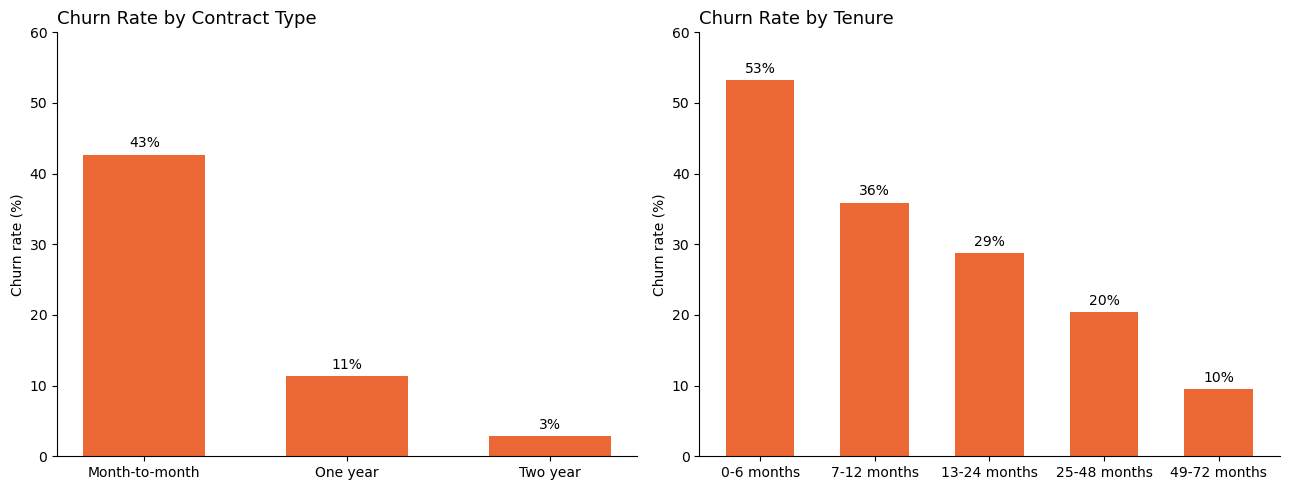

In [13]:
# chart the two strongest segment signals side by side
CHURN_COLOR = '#eb6834'
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, data, col, title in [
    (axes[0], df_contract, 'Contract', 'Churn Rate by Contract Type'),
    (axes[1], df_tenure, 'tenure_band', 'Churn Rate by Tenure'),
]:
    labels = data[col].str.replace(r'^\d+: ', '', regex=True)
    bars = ax.bar(labels, data['churn_rate_pct'], color=CHURN_COLOR, width=0.6)
    ax.bar_label(bars, labels=[f'{v:.0f}%' for v in data['churn_rate_pct']], padding=3)
    ax.set_title(title, loc='left', fontsize=13)
    ax.set_ylabel('Churn rate (%)')
    ax.set_ylim(0, 60)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', labelrotation=0)

plt.tight_layout()
plt.show()

### 2h. Where churn concentrates: contract x tenure heatmap
Each cell shows the churn rate and the number of customers. Darker = higher churn. Cells with few customers (for example, two-year contracts in the first 6 months) should be read with caution.

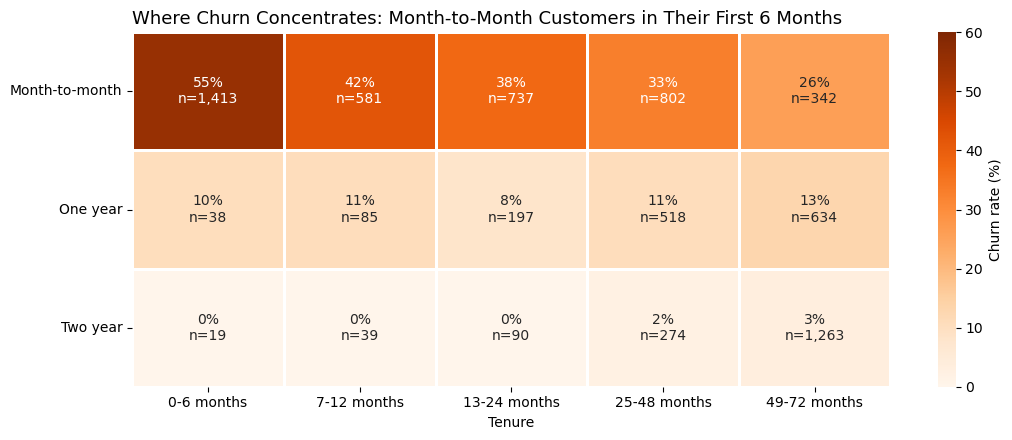

In [14]:
# churn rate and customer count for every contract x tenure combination
df_heat = run_sql('''
SELECT
    Contract,
    tenure_band,
    COUNT(*)                           AS customers,
    ROUND(100.0 * AVG(churn_flag), 1)  AS churn_rate_pct
FROM customer_features
GROUP BY Contract, tenure_band
''')

# pivot so contracts are rows and tenure bands are columns
heat_rate = df_heat.pivot(index='Contract', columns='tenure_band', values='churn_rate_pct')
heat_count = df_heat.pivot(index='Contract', columns='tenure_band', values='customers')
heat_rate.columns = heat_rate.columns.str.replace(r'^\d+: ', '', regex=True)

# label each cell with the churn rate and the number of customers
labels = heat_rate.round(0).astype(int).astype(str) + '%\n' + 'n=' + heat_count.map('{:,}'.format).values

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(heat_rate, annot=labels.values, fmt='', cmap='Oranges', vmin=0, vmax=60,
            linewidths=2, linecolor='white', cbar_kws={'label': 'Churn rate (%)'}, ax=ax)
ax.set_title('Where Churn Concentrates: Month-to-Month Customers in Their First 6 Months', loc='left', fontsize=13)
ax.set_xlabel('Tenure')
ax.set_ylabel('')
ax.tick_params(axis='y', labelrotation=0)
plt.tight_layout()
plt.show()

### 2i. Engaged customers stay
Churn rate by number of add-on services, internet customers only (from the 2f query).

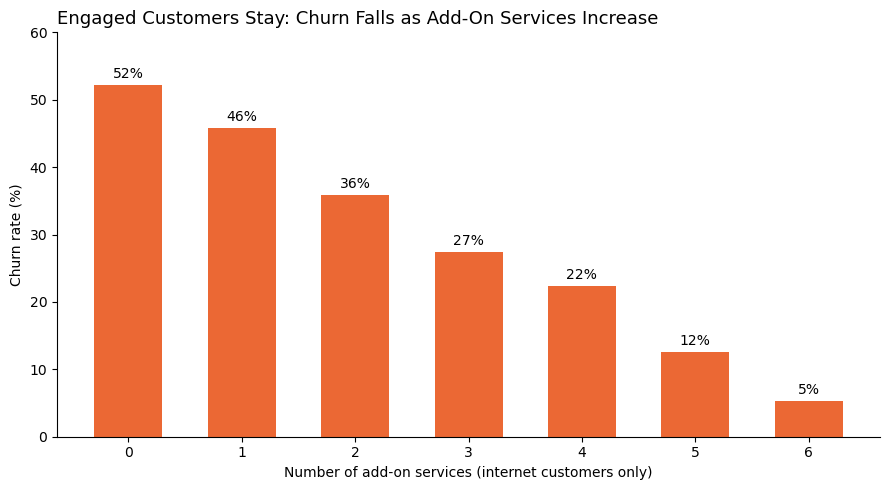

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(df_addons['num_addons'].astype(str), df_addons['churn_rate_pct'], color=CHURN_COLOR, width=0.6)
ax.bar_label(bars, labels=[f'{v:.0f}%' for v in df_addons['churn_rate_pct']], padding=3)
ax.set_title('Engaged Customers Stay: Churn Falls as Add-On Services Increase', loc='left', fontsize=13)
ax.set_xlabel('Number of add-on services (internet customers only)')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 60)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### 2j. Stacking risk and protective factors
How churn changes as customers have more of the strongest drivers at once (from the logistic regression in section 3c):
- **Biggest risks:** fiber optic internet, electronic check
- **Biggest protectors:** long tenure (49+ months), two-year contract

In [16]:
# churn rate as each factor is added: UNION ALL stacks each step, then one GROUP BY summarizes them
df_stack = run_sql('''
WITH steps AS (
    SELECT 'Risk'    AS stack, 1 AS step, 'All customers'                   AS customers_with, churn_flag FROM customer_features
    UNION ALL
    SELECT 'Risk',    2, '+ Fiber optic',                    churn_flag FROM customer_features
        WHERE InternetService = 'Fiber optic'
    UNION ALL
    SELECT 'Risk',    3, '+ Fiber optic + Electronic check', churn_flag FROM customer_features
        WHERE InternetService = 'Fiber optic' AND PaymentMethod = 'Electronic check'
    UNION ALL
    SELECT 'Protect', 1, 'All customers',                    churn_flag FROM customer_features
    UNION ALL
    SELECT 'Protect', 2, '+ Tenure 49+ months',              churn_flag FROM customer_features
        WHERE tenure > 48
    UNION ALL
    SELECT 'Protect', 3, '+ Tenure 49+ months + Two-year',   churn_flag FROM customer_features
        WHERE tenure > 48 AND Contract = 'Two year'
)
SELECT
    stack,
    step,
    customers_with,
    COUNT(*)                           AS customers,
    ROUND(100.0 * AVG(churn_flag), 1)  AS churn_rate_pct
FROM steps
GROUP BY stack, step, customers_with
ORDER BY stack DESC, step
''')
df_stack

,stack,step,customers_with,customers,churn_rate_pct
0,Risk,1,All customers,7032,26.6
1,Risk,2,+ Fiber optic,3096,41.9
2,Risk,3,+ Fiber optic + Electronic check,1595,53.2
3,Protect,1,All customers,7032,26.6
4,Protect,2,+ Tenure 49+ months,2239,9.5
5,Protect,3,+ Tenure 49+ months + Two-year,1263,3.3


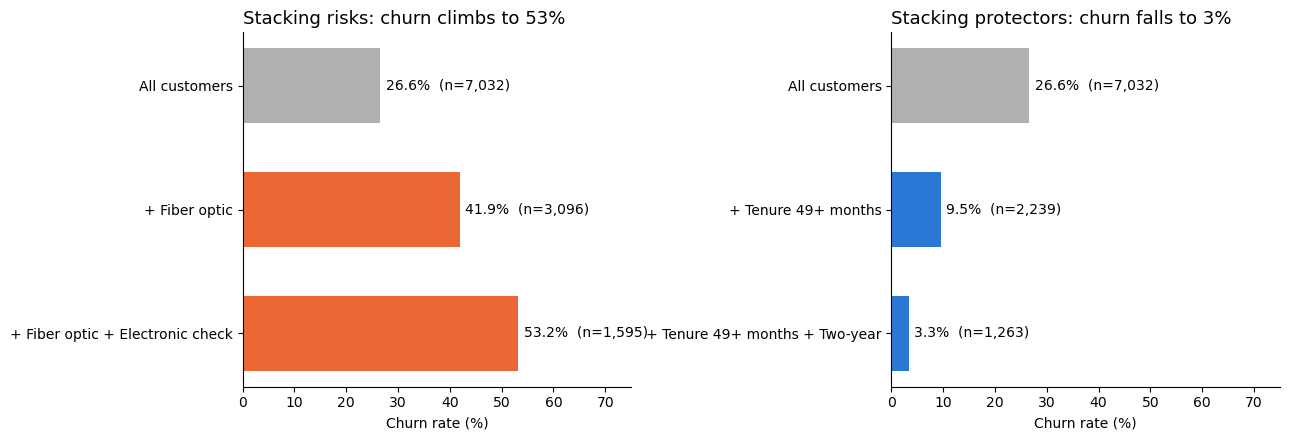

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, stack, color, title in [
    (axes[0], 'Risk', CHURN_COLOR, 'Stacking risks: churn climbs to 53%'),
    (axes[1], 'Protect', '#2a78d6', 'Stacking protectors: churn falls to 3%'),
]:
    data = df_stack[df_stack['stack'] == stack].sort_values('step', ascending=False)
    colors = ['#b0b0b0' if s == 1 else color for s in data['step']]
    bars = ax.barh(data['customers_with'], data['churn_rate_pct'], color=colors, height=0.6)
    ax.bar_label(bars, labels=[f"{r:.1f}%  (n={n:,})" for r, n in zip(data['churn_rate_pct'], data['customers'])], padding=4)
    ax.set_title(title, loc='left', fontsize=13)
    ax.set_xlim(0, 75)
    ax.set_xlabel('Churn rate (%)')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

Risks stack: 26.6% overall, 41.9% for fiber customers, 53.2% for fiber customers who also pay by electronic check. Protectors stack too: 9.5% for customers with 49+ months of tenure and 3.3% when they are also on a two-year contract. (Two-year contracts alone are already at 2.8%, so most of that protection comes from the contract itself.)

### 2k. Each driver split by contract and by internet type
Churn rate for customers who have each feature, broken out by contract type and by internet service. Each cell also shows the number of customers. Blank cells mean no customers fit (for example, streaming requires internet).

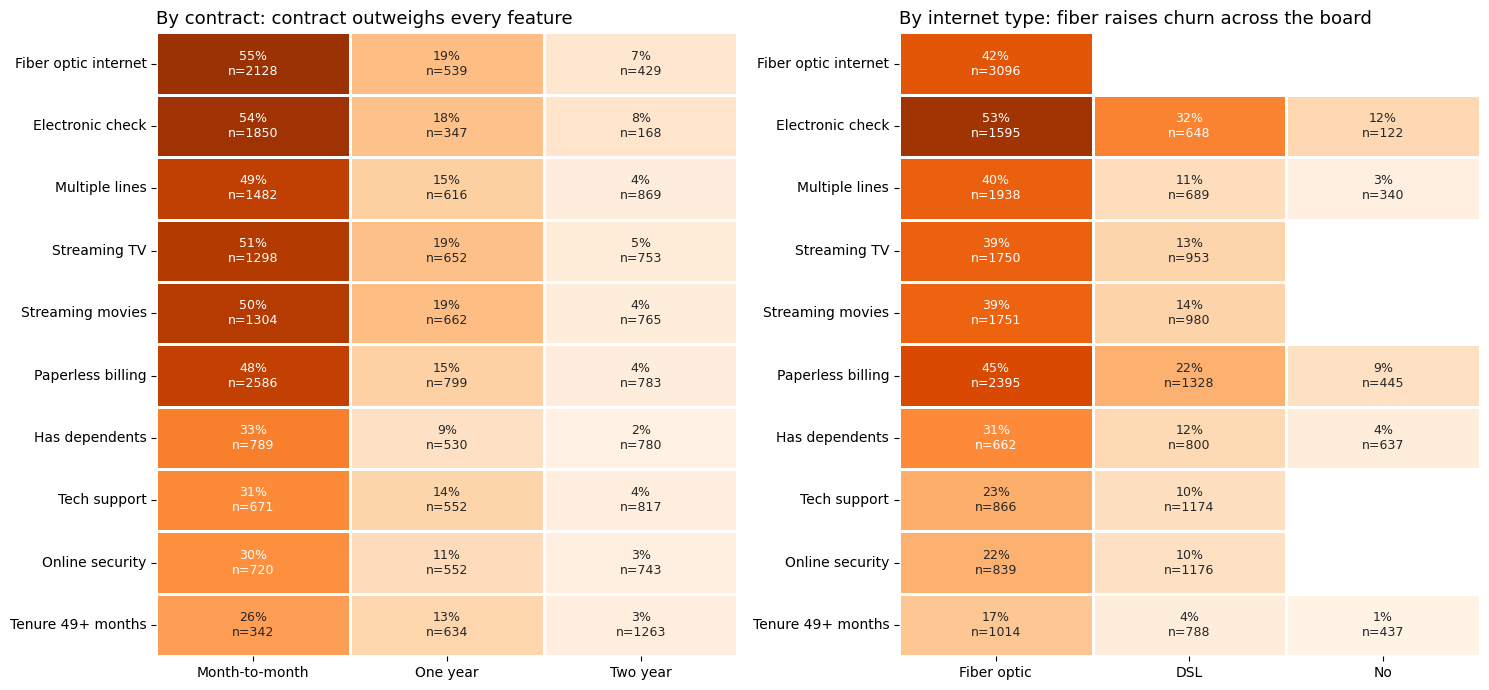

In [18]:
# pull the feature view, then build a yes/no flag for each driver
df_feat = run_sql('SELECT * FROM customer_features')
drivers = {
    'Fiber optic internet': df_feat['InternetService'] == 'Fiber optic',
    'Electronic check':     df_feat['PaymentMethod'] == 'Electronic check',
    'Multiple lines':       df_feat['MultipleLines'] == 'Yes',
    'Streaming TV':         df_feat['StreamingTV'] == 'Yes',
    'Streaming movies':     df_feat['StreamingMovies'] == 'Yes',
    'Paperless billing':    df_feat['PaperlessBilling'] == 'Yes',
    'Has dependents':       df_feat['Dependents'] == 'Yes',
    'Tech support':         df_feat['TechSupport'] == 'Yes',
    'Online security':      df_feat['OnlineSecurity'] == 'Yes',
    'Tenure 49+ months':    df_feat['tenure'] > 48,
}

def driver_split(split_col, order):
    # churn rate and customer count for each driver x split group
    rate = pd.DataFrame(index=list(drivers), columns=order, dtype=float)
    count = pd.DataFrame(index=list(drivers), columns=order, dtype=float)
    for name, has_feature in drivers.items():
        for group in order:
            subset = df_feat[has_feature & (df_feat[split_col] == group)]
            count.loc[name, group] = len(subset)
            rate.loc[name, group] = 100 * subset['churn_flag'].mean() if len(subset) else np.nan
    return rate, count

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, split_col, order, title in [
    (axes[0], 'Contract', ['Month-to-month', 'One year', 'Two year'], 'By contract: contract outweighs every feature'),
    (axes[1], 'InternetService', ['Fiber optic', 'DSL', 'No'], 'By internet type: fiber raises churn across the board'),
]:
    rate, count = driver_split(split_col, order)
    labels = rate.round(0).astype('Int64').astype(str).replace('<NA>', '') + '%\n' + 'n=' + count.astype(int).astype(str)
    labels = labels.where(count > 0, '')
    sns.heatmap(rate, annot=labels.values, fmt='', cmap='Oranges', vmin=0, vmax=60, linewidths=2, linecolor='white',
                cbar=False, ax=ax, annot_kws={'fontsize': 9})
    ax.set_title(title, loc='left', fontsize=13)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='y', labelrotation=0)
plt.tight_layout()
plt.show()

**Findings:**
- **Contract outweighs any single feature.** Even customers with "protective" features churn at about 30% on month-to-month contracts (tech support 30.7%, online security 29.6%), while fiber customers on two-year contracts churn at only 7.2%.
- **Fiber raises churn in every group.** For example, customers with 49+ months of tenure churn at 17.1% on fiber vs. 4.3% on DSL, and electronic check payers churn at 53.2% on fiber vs. 31.9% on DSL.
- **Takeaway for retention:** moving customers off month-to-month contracts is the single biggest lever, and fiber customers need a closer look (price, service quality or competition).

### SQL findings
- **26.6% of customers churned** (1,869 of 7,032), taking about **$139K in monthly charges**, or roughly **$1.67M a year**.
- **Contract type is the biggest signal.** Month-to-month customers churn at **42.7%**, compared with 11.3% for one-year and 2.8% for two-year contracts. They make up **88.6% of all churners**.
- **The first 6 months are the danger zone.** Churn is **53.3%** for customers in their first 6 months and drops steadily to 9.5% after 4 years. The first 6 months account for 41.9% of all churners.
- **Electronic check payers churn at 45.3%**, compared with 15 to 19% for the other payment methods.
- **Engaged customers stay.** Internet customers with no add-on services churn at 52.2%. Customers with all six churn at 5.3%, even though they pay more each month.
- **One segment stands out:** month-to-month customers in their first 6 months account for **$49.7K a month in lost revenue**, about 36% of the total.

## 3. Python: can we predict churn?

The modeling table is pulled straight from the SQL view, so the SQL work and the model use the same definitions.

In [19]:
# import modeling libraries
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

In [20]:
# pull the modeling table from SQL
df_model = run_sql('SELECT * FROM customer_features')

# target: 1 = churned
y = df_model['churn_flag']

# features: drop the ID and target columns, plus fields that duplicate other features:
#   tenure_band    -> tenure is already included as a number
#   num_addons     -> the six add-on columns are already included
#   MonthlyCharges -> set by the services a customer picks, which are already included
#   TotalCharges   -> roughly tenure x MonthlyCharges
X = df_model.drop(columns=['customerID', 'Churn', 'churn_flag', 'tenure_band',
                           'num_addons', 'MonthlyCharges', 'TotalCharges'])
X = pd.get_dummies(X, drop_first=True, dtype=int)  # drop_first avoids multicollinearity
X.shape

(7032, 28)

In [21]:
# split into training (80%) and test (20%) sets
# stratify=y keeps the same churn rate in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f'Training churn rate: {y_train.mean():.1%}   Test churn rate: {y_test.mean():.1%}')

Training churn rate: 26.6%   Test churn rate: 26.6%


### 3a. Models compared

- **Baseline:** always predicts "no churn". Any useful model has to beat this.
- **Random Forest (original settings):** the model from the original coursework version, for comparison.
- **Logistic Regression:** easy to explain; each feature gets a direction and strength.
- **Decision Tree:** limited to 4 levels to keep it simple and avoid overfitting.
- **Random Forest (tuned):** tuned with GridSearchCV.

Only about 27% of customers churn, so the models are fit with `class_weight='balanced'`. This tells the model that missing a churner is as costly as a false alarm, which raises **recall** (the share of churners caught). For a retention team, recall matters more than raw accuracy.

In [22]:
# tune the random forest with 5-fold cross validation, scoring on ROC AUC
rf_grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
    param_grid={'max_depth': [5, 8, 12], 'min_samples_leaf': [1, 5, 10]},
    scoring='roc_auc', cv=5, n_jobs=-1
)
rf_grid.fit(X_train, y_train)
print('Best random forest settings:', rf_grid.best_params_)

Best random forest settings: {'max_depth': 12, 'min_samples_leaf': 10}


In [23]:
models = {
    'Baseline (always "no churn")': DummyClassifier(strategy='most_frequent'),
    'Random Forest (original settings)': RandomForestClassifier(n_estimators=100, random_state=42),
    'Logistic Regression': make_pipeline(StandardScaler(),
                                         LogisticRegression(class_weight='balanced', max_iter=1000)),
    'Decision Tree (4 levels)': DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42),
    'Random Forest (tuned)': rf_grid.best_estimator_,
}

# fit each model and collect test set metrics
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, prob),
    })

df_results = pd.DataFrame(results).set_index('model').round(3)
df_results

,accuracy,precision,recall,f1,roc_auc
model,,,,,
"Baseline (always ""no churn"")",0.734,0.000,0.000,0.000,0.500
Random Forest (original settings),0.780,0.605,0.495,0.544,0.810
Logistic Regression,0.730,0.495,0.786,0.607,0.833
Decision Tree (4 levels),0.731,0.497,0.781,0.607,0.816
Random Forest (tuned),0.750,0.519,0.791,0.627,0.837


### Model comparison findings
- **Accuracy alone is misleading here.** The baseline is 73.4% accurate but catches **zero** churners.
- **The original random forest** has the highest accuracy (78.0%) but only catches **49.5%** of churners.
- **With class balancing**, logistic regression catches **78.6%** of churners and the tuned random forest catches **79.1%**. Their ROC AUC scores are nearly identical (0.833 vs. 0.837).
- **Chosen model: Logistic Regression.** It performs almost the same as the tuned random forest, but:
    - every driver has a clear direction and size that can be explained to non-technical stakeholders
    - the scoring is a simple formula that could run in SQL or Excel, so it doesn't need special software once it's built
- **The trade-off** is more false alarms: about half of the flagged customers (precision 49.5%) actually churned. For a retention offer that is usually acceptable, since a missed churner costs far more than an unneeded offer. The threshold table below shows how to shift this balance.

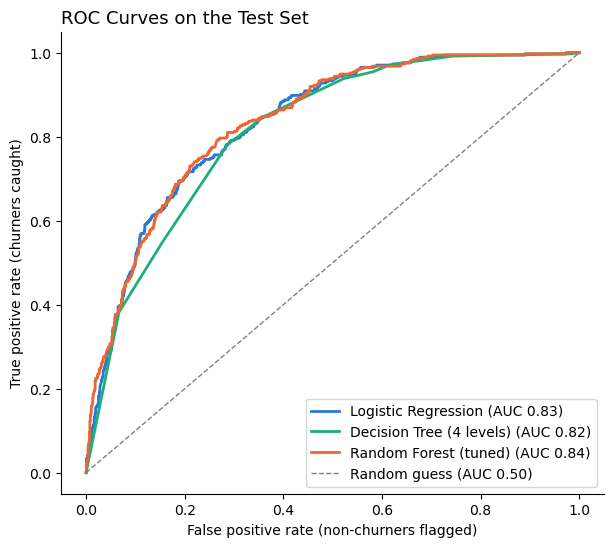

In [24]:
# ROC curves: how well each model ranks churners above non-churners at every threshold
fig, ax = plt.subplots(figsize=(7, 6))
roc_colors = {'Logistic Regression': '#2a78d6', 'Decision Tree (4 levels)': '#1baf7a', 'Random Forest (tuned)': '#eb6834'}
for name, color in roc_colors.items():
    fpr, tpr, _ = roc_curve(y_test, models[name].predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC {df_results.loc[name, 'roc_auc']:.2f})")
ax.plot([0, 1], [0, 1], color='grey', linestyle='--', linewidth=1, label='Random guess (AUC 0.50)')
ax.set_xlabel('False positive rate (non-churners flagged)')
ax.set_ylabel('True positive rate (churners caught)')
ax.set_title('ROC Curves on the Test Set', loc='left', fontsize=13)
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

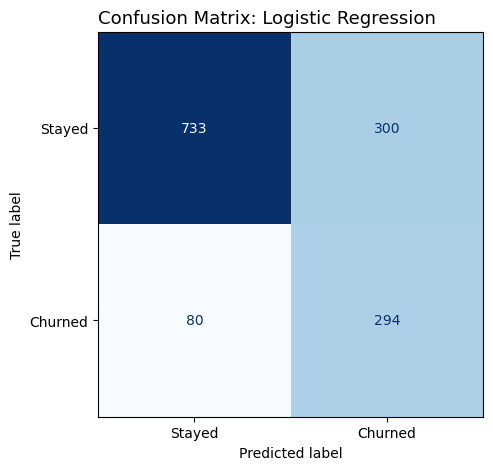

Churners caught: 294 of 374   Missed: 80   False alarms: 300   Correctly left alone: 733


In [25]:
# confusion matrix for the chosen model
final_name = 'Logistic Regression'
final_model = models[final_name]

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test,
                                      display_labels=['Stayed', 'Churned'], cmap='Blues', colorbar=False, ax=ax)
ax.set_title(f'Confusion Matrix: {final_name}', loc='left', fontsize=13)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, final_model.predict(X_test)).ravel()
print(f'Churners caught: {tp} of {tp + fn}   Missed: {fn}   False alarms: {fp}   Correctly left alone: {tn}')

### 3b. Choosing the threshold

By default a customer is flagged when their predicted churn probability is 50% or more. The cutoff is a business decision: a lower cutoff catches more churners but sends more offers to customers who were going to stay.

In [26]:
test_prob = final_model.predict_proba(X_test)[:, 1]
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (test_prob >= t).astype(int)
    rows.append({
        'threshold': t,
        'customers_flagged': pred_t.sum(),
        'churners_caught': int(((pred_t == 1) & (y_test == 1)).sum()),
        'recall': recall_score(y_test, pred_t),
        'precision': precision_score(y_test, pred_t),
    })
pd.DataFrame(rows).round(3)

,threshold,customers_flagged,churners_caught,recall,precision
0,0.3,837,346,0.925,0.413
1,0.4,703,318,0.850,0.452
2,0.5,594,294,0.786,0.495
3,0.6,484,268,0.717,0.554
4,0.7,373,230,0.615,0.617


### 3c. What drives churn?

Logistic regression coefficients are converted to **odds ratios**. Because the features are standardized, each odds ratio shows how the odds of churning change for a one standard deviation increase in that feature (for yes/no features, roughly "having it vs. not"). Above 1 = more likely to churn, below 1 = less likely.

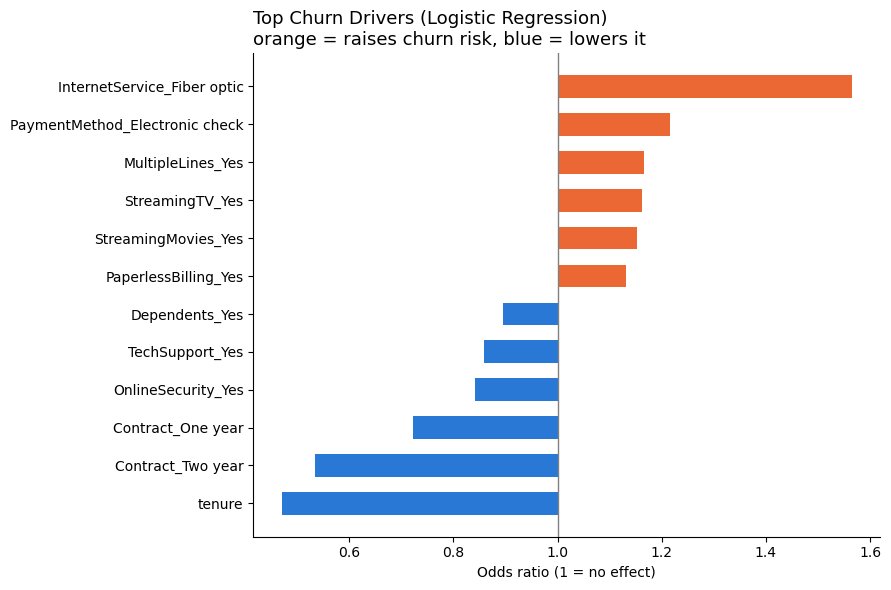

,feature,odds_ratio
8,InternetService_Fiber optic,1.56
26,PaymentMethod_Electronic check,1.22
7,MultipleLines_Yes,1.17
19,StreamingTV_Yes,1.16
21,StreamingMovies_Yes,1.15
24,PaperlessBilling_Yes,1.13
4,Dependents_Yes,0.90
17,TechSupport_Yes,0.86
11,OnlineSecurity_Yes,0.84
22,Contract_One year,0.72


In [27]:
logreg = models['Logistic Regression'][-1]
df_odds = pd.DataFrame({'feature': X.columns, 'odds_ratio': np.exp(logreg.coef_[0])})
df_odds['distance_from_1'] = np.abs(np.log(df_odds['odds_ratio']))
top_drivers = df_odds.sort_values('distance_from_1', ascending=False).head(12).sort_values('odds_ratio')

fig, ax = plt.subplots(figsize=(9, 6))
colors = ['#eb6834' if v > 1 else '#2a78d6' for v in top_drivers['odds_ratio']]
ax.barh(top_drivers['feature'], top_drivers['odds_ratio'] - 1, left=1, color=colors, height=0.6)
ax.axvline(1, color='grey', linewidth=1)
ax.set_xlabel('Odds ratio (1 = no effect)')
ax.set_title('Top Churn Drivers (Logistic Regression)\norange = raises churn risk, blue = lowers it', loc='left', fontsize=13)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

top_drivers[['feature', 'odds_ratio']].sort_values('odds_ratio', ascending=False).round(2)

In [28]:
# random forest feature importance as a second opinion
rf_importance = pd.Series(models['Random Forest (tuned)'].feature_importances_, index=X.columns)
rf_importance.sort_values(ascending=False).head(10).round(3)

tenure                              0.240
Contract_Two year                   0.143
InternetService_Fiber optic         0.091
PaymentMethod_Electronic check      0.080
Contract_One year                   0.060
OnlineSecurity_Yes                  0.049
TechSupport_Yes                     0.035
OnlineBackup_No internet service    0.021
OnlineBackup_Yes                    0.020
StreamingTV_No internet service     0.020
dtype: float64

### Driver findings
- **Tenure and contract length protect against churn the most.** A two-year contract cuts the odds of churning roughly in half (odds ratio 0.53).
- **Fiber optic customers are more likely to churn** (odds ratio 1.56). The data can't say why (price, service quality, competition), so this is a question for the business.
- **Electronic check payers are more likely to churn** (1.22), which matches the SQL finding.
- **Online security and tech support are "sticky."** Customers who have them are less likely to leave.
- **The random forest agrees:** its top four features are tenure, two-year contract, fiber optic and electronic check.
- *These are associations, not proof of cause. Testing an intervention (section 5) is how to confirm what actually reduces churn.*

## 4. Who should the retention team call first?

Every customer gets a churn probability using 5-fold cross validation (`cross_val_predict`), so each score comes from a model that never saw that customer. The focus is on **customers who are still active**: they look like the ones who left, and there is still time to keep them.

**Expected monthly revenue at risk = churn probability x monthly charges.** This puts high-risk, high-value customers at the top of the list.

In [29]:
# out-of-fold churn probabilities for every customer
df_model['churn_prob'] = cross_val_predict(final_model, X, y, cv=5, method='predict_proba')[:, 1]
df_model['expected_revenue_at_risk'] = df_model['churn_prob'] * df_model['MonthlyCharges']

# risk tiers based on probability
df_model['risk_tier'] = pd.cut(df_model['churn_prob'], bins=[0, 0.4, 0.7, 1.0],
                               labels=['3: Low (<40%)', '2: Medium (40-70%)', '1: High (70%+)'], include_lowest=True)

# write the scores back to SQL so the business can query them
df_model[['customerID', 'Contract', 'tenure', 'MonthlyCharges', 'churn_flag', 'churn_prob',
          'expected_revenue_at_risk', 'risk_tier']].astype({'risk_tier': str}).to_sql('risk_scores', conn, index=False);

In [30]:
# check: do the risk tiers line up with what actually happened?
run_sql('''
SELECT
    risk_tier,
    COUNT(*)                           AS customers,
    ROUND(100.0 * AVG(churn_flag), 1)  AS actual_churn_rate_pct
FROM risk_scores
GROUP BY risk_tier
ORDER BY risk_tier
''')

,risk_tier,customers,actual_churn_rate_pct
0,1: High (70%+),1749,62.6
1,2: Medium (40-70%),1679,30.6
2,3: Low (<40%),3604,7.2


In [31]:
# active customers only: how much revenue is at risk in each tier?
run_sql('''
SELECT
    risk_tier,
    COUNT(*)                                   AS active_customers,
    ROUND(AVG(churn_prob) * 100, 1)            AS avg_churn_prob_pct,
    ROUND(SUM(MonthlyCharges), 0)              AS monthly_revenue,
    ROUND(SUM(expected_revenue_at_risk), 0)    AS expected_monthly_revenue_at_risk
FROM risk_scores
WHERE churn_flag = 0
GROUP BY risk_tier
ORDER BY risk_tier
''')

,risk_tier,active_customers,avg_churn_prob_pct,monthly_revenue,expected_monthly_revenue_at_risk
0,1: High (70%+),655,79.8,53097.0,42513.0
1,2: Medium (40-70%),1165,54.0,78368.0,42674.0
2,3: Low (<40%),3343,14.8,185066.0,28898.0


In [32]:
# the retention team's call list: top 10 active customers by expected revenue at risk
run_sql('''
SELECT
    customerID,
    Contract,
    tenure,
    MonthlyCharges,
    ROUND(churn_prob * 100, 1)              AS churn_prob_pct,
    ROUND(expected_revenue_at_risk, 2)      AS expected_revenue_at_risk
FROM risk_scores
WHERE churn_flag = 0
ORDER BY expected_revenue_at_risk DESC
LIMIT 10
''')

,customerID,Contract,tenure,MonthlyCharges,churn_prob_pct,expected_revenue_at_risk
0,3292-PBZEJ,Month-to-month,11,111.40,90.5,100.87
1,2081-VEYEH,Month-to-month,3,107.95,87.8,94.74
2,6734-GMPVK,Month-to-month,5,105.30,89.3,93.98
3,5956-YHHRX,Month-to-month,21,104.35,89.0,92.91
4,7145-FEJWU,Month-to-month,12,105.30,88.2,92.88
5,5995-SNNEW,Month-to-month,23,104.45,88.5,92.43
6,6030-REHUX,Month-to-month,28,110.85,83.4,92.41
7,0771-WLCLA,Month-to-month,16,112.95,81.1,91.57
8,5760-IFJOZ,Month-to-month,3,107.95,84.7,91.47
9,0365-BZUWY,Month-to-month,17,102.55,88.4,90.68


### Risk scoring findings
- **The tiers line up with reality:** 62.6% of High-tier customers actually churned, compared with 30.6% of Medium and 7.2% of Low.
- **655 active customers are High risk**, paying **$53.1K a month** in total.
- **The top of the call list** is all month-to-month customers paying over $100 a month, mostly in their first two years.
- **Caveat:** class balancing pushes the predicted probabilities up. High-tier customers average a predicted 79.8%, but 62.6% actually churned. Use the scores to **rank and prioritize** customers, not as exact forecasts. Calibrating the probabilities is listed as a next step.

## 5. Recommendations

| Finding | Recommended action | How to measure it |
|---|---|---|
| Month-to-month customers are 89% of churners | Offer an incentive to move High-risk month-to-month customers to a one-year contract | Contract conversion rate, churn rate vs. a control group |
| Churn is 53% in the first 6 months | Build an onboarding program (check-ins, setup help) for new customers | 6-month churn rate for new customers before vs. after |
| Security and tech support customers stay | Offer a free trial of these add-ons to new internet customers | Add-on adoption, churn of trial vs. non-trial customers |
| Electronic check payers churn at 45% | Encourage a switch to automatic payment | Autopay adoption, churn among switchers |
| Fiber optic customers churn more | Investigate with the product team (pricing, outages, competitor offers) | Root cause findings, then a targeted test |

**Proving it works:** for each action, hold back a random control group of similar High-risk customers who don't get the offer. Comparing churn between the two groups shows the real impact, separate from any other changes.

## 6. Limitations and next steps
- **Snapshot data:** there is one row per customer with no history, so the model can't see changes in behavior over time (for example, a drop in usage before leaving).
- **Voluntary vs. involuntary churn:** the data doesn't separate customers who chose to leave from those cut off for non-payment, which need different actions.
- **Sample dataset:** this is IBM's sample telco data, so the results show the method rather than a real company's numbers.
- **Next steps:**
    - calibrate the probabilities so they can be read as true likelihoods
    - set the threshold using the actual cost of an offer vs. the value of a saved customer
    - rescore customers monthly and track whether model performance holds up

## 7. Export the scored customers

One customer-level file with the original fields, the SQL features (`tenure_band`, `num_addons`), the model outputs (`churn_prob`, `expected_revenue_at_risk`, `risk_tier`), and two reporting fields:
- `customer_status`: Active or Churned, easier to read than Yes/No
- `churn_rate_pct`: 100 if the customer churned, 0 if not, so its average in Power BI is the churn rate as a percent

It can be loaded into SQL Server as the `churn_risk_scores` table or used as the data source for a Power BI dashboard. Rerunning this notebook on new data refreshes the file.

In [33]:
# combine the customer fields with the model outputs and save to CSV
df_export = df_model.drop(columns=['churn_flag'])
df_export['customer_status'] = np.where(df_model['churn_flag'] == 1, 'Churned', 'Active')
df_export['churn_rate_pct'] = df_model['churn_flag'] * 100
df_export['risk_tier'] = df_export['risk_tier'].astype(str)
df_export['churn_prob'] = df_export['churn_prob'].round(4)
df_export['expected_revenue_at_risk'] = df_export['expected_revenue_at_risk'].round(2)
df_export.to_csv('churn_risk_scores.csv', index=False)
df_export.shape

(7032, 28)

In [34]:
# close the database connection
conn.close()